# Store Sales Forecasting for Corporación Favorita

UW ECON 481A · Autumn 2026

**Research question.** Which forecasting method best predicts the next 16 days of sales for each store and product family? Does knowing the promotion schedule change which method to use?

**Answer from the recorded backtest.** The pretrained time-series model t0-beta with promotions achieved **0.41312 RMSLE**, compared with **0.48376** for Prophet with promotions and **0.61704** for seasonal naïve. The foundation model also beat Prophet in the sales-history-only comparison. Adding promotions to t0-beta improved RMSLE and increased mean absolute error by 0.63 sales units on the final holdout.

Corporación Favorita operates grocery stores in Ecuador. Store managers can use sales forecasts to plan replenishment and staffing. Recorded sales depend on both customer demand and inventory availability, so the forecast evaluation measures accuracy on observed sales. [Kaggle competition](https://www.kaggle.com/competitions/store-sales-time-series-forecasting) · [Course Decision Loop](https://eisenhauerio.github.io/courses-business-decisions/decision-loop/index.html)

## Reproduce the notebook

This notebook reads the run specified by `ECON481_RESULTS`. The defaults are `results/official` and then the checked-in aggregate results in `files/official-results`. If neither is present, a small deterministic fixture verifies the workflow. Fixture scores are labeled as generated data. The discussion of the recorded run refers to the official result bundle.

GitHub Actions checks the code and executes the notebook from top to bottom using the saved official aggregates. The full model run uses the separately obtained Kaggle archive, repeated Prophet fits, and a downloaded model checkpoint. This arrangement lets a reviewer reproduce the tables without downloading competition data in CI. To regenerate predictions after obtaining the archive, follow the [README](README.md) or run the recorded settings below. The manifest records the exact checkpoint, file hashes, original Python and package versions, and the two-job execution setup.

~~~bash
python -m pip install 'tfc-t0[torch]==0.6.1'
OMP_NUM_THREADS=4 python -m auxiliary.run --data data/raw/store-sales-time-series-forecasting.zip \
  --output-dir results/official --device cpu --jobs 8 --make-submission
~~~

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

official_directories = (Path("results/official"), Path("files/official-results"))
saved_official = next(
    (
        directory
        for directory in official_directories
        if (directory / "manifest.json").is_file()
    ),
    None,
)
requested_results = os.environ.get("ECON481_RESULTS")

if requested_results:
    results_directory = Path(requested_results)
elif saved_official is not None:
    results_directory = saved_official
else:
    results_directory = Path("results/fixture")
    subprocess.run(
        [
            sys.executable,
            "-m",
            "auxiliary.run",
            "--fixture",
            "--output-dir",
            str(results_directory),
        ],
        check=True,
    )

with (results_directory / "manifest.json").open(encoding="utf-8") as handle:
    manifest = json.load(handle)

dataset_labels = {
    "fixture": "Generated fixture — workflow verification",
    "kaggle_store_sales": "Official Kaggle Store Sales data",
}
dataset = manifest["dataset"]
if dataset not in dataset_labels:
    raise ValueError(f"Unrecognized dataset provenance: {dataset!r}")

if results_directory in official_directories and dataset != "kaggle_store_sales":
    raise ValueError(f"Expected official Kaggle provenance in {results_directory}")

display(Markdown(f"**Data source for these outputs:** {dataset_labels[dataset]}"))
if dataset == "kaggle_store_sales":
    data_files = manifest["data"]["files"]
    gaps = manifest["data"]["missing_training_dates"]
    display(
        Markdown(
            f"**Labeled rows:** {data_files['train.csv']['rows']:,}  \n"
            f"**Competition test IDs:** {data_files['test.csv']['rows']:,}  \n"
            f"**Calendar dates with no training rows:** {', '.join(gaps)}"
        )
    )

scores = pd.read_csv(results_directory / "scores.csv")
slices = pd.read_csv(results_directory / "slices.csv")

**Data source for these outputs:** Official Kaggle Store Sales data

**Labeled rows:** 3,000,888  
**Competition test IDs:** 28,512  
**Calendar dates with no training rows:** 2013-12-25, 2014-12-25, 2015-12-25, 2016-12-25

## Forecasting design

The competition target is nonnegative daily unit sales for each store and product family. Units can be fractional. Data checks cover the expected date and key structure. The competition horizon is verified against the test records. Every model receives the same forecast dates and scoring rows within a window.

The benchmark creates three contiguous rolling-origin forecast windows. At each origin, models can use up to 512 trailing calendar days of history ending before the first forecast date. A model makes all daily predictions for the horizon using the information available at the origin. The first two windows are for development. Select a configuration using the lowest pooled development RMSLE, then score all prespecified variants on the last window. Realized sales in a window are used to score forecasts after prediction. [Kaggle data description](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data)

The panel covers 54 stores and 33 product families. Four December 25 dates have no training rows in the official archive. They remain missing on the daily axis. Seasonal baselines skip unavailable observations, Prophet fits observed dates, and t0-beta sees missing positions in its sequence. A recorded sale of zero is an observation. The model inputs exclude test-period sales. The forecast file uses the official test ID order.

In [2]:
date_columns = ["train_end", "forecast_start", "forecast_end"]
windows = (
    scores[["fold", *date_columns]]
    .drop_duplicates()
    .sort_values("forecast_start")
    .reset_index(drop=True)
)
holdout_fold = windows.iloc[-1]["fold"]
display(windows)
display(
    Markdown(
        f"**Forecast horizon:** {manifest['horizon']} days  \n"
        f"**Number of store–family series:** {manifest['n_series']:,}"
    )
)

,fold,train_end,forecast_start,forecast_end
0,validation_1,2017-06-28,2017-06-29,2017-07-14
1,validation_2,2017-07-14,2017-07-15,2017-07-30
2,holdout,2017-07-30,2017-07-31,2017-08-15


**Forecast horizon:** 16 days  
**Number of store–family series:** 1,782

## Model specifications

| Model | Forecasting method | Inputs for the forecast horizon |
| --- | --- | --- |
| Seasonal naïve | Repeat the last observed value for each weekday | Calendar alignment |
| Recent weekday mean | Average up to eight recent same-weekday observations on the log-sales scale. Use the latest available same-weekday observation when all eight are missing. | Calendar alignment |
| Prophet | Separate additive trend and seasonal fits to log-transformed sales, by store and family | Calendar alignment |
| Prophet, less flexible trend | Reduce the changepoint prior scale from 0.05 to 0.02 | Calendar alignment |
| t0-beta | Frozen pretrained patch transformer, using its median forecast on log-transformed sales | Daily sequence positions |
| Promotion variants | Fit Prophet with a promotion regressor and supply promotion counts to t0-beta through its known-future covariate interface | Each model's time input and promotion counts |

Use the trailing 512 days of sales for Prophet and t0-beta and return predictions to original sales units. The sales-history comparison asks what each method can do with historical sales. A smaller changepoint prior scale makes Prophet's trend less flexible. The two settings test whether reducing trend flexibility improves short-horizon accuracy. The promotion comparison assumes the recorded promotional schedule was available at the origin. The historical file does not give a dated snapshot of each plan. Realized future oil prices and transactions are excluded. Prophet includes the regressor where it varies in the fitted history. The t0 runtime can drop constant covariates. Neither approach estimates the causal effect of putting an item on promotion.

Prophet learns a separate trend and weekly and yearly components from each store–family history. t0-beta uses fixed weights learned before this project and predicts from each series context without fitting new weights. Both forecast on the log-sales scale, return to sales units, and are scored with the same rules. The shared log transform does not establish which architectural choice is responsible for the resulting gap.

The Forecasting Company reports that t0-beta's pretraining excluded the datasets declared by fev-bench, which lists Favorita Store Sales. It reports Favorita overlap for t0-alpha. Pin the beta model revision for this experiment. The exclusion claim comes from the developers' disclosures. Access to a complete independently audited training corpus was unavailable. [Prophet paper](https://doi.org/10.1080/00031305.2017.1380080) · [t0-beta model card](https://huggingface.co/theforecastingcompany/t0-beta) · [t0 technical report §5.1.2](https://arxiv.org/pdf/2609.24559) · [fev-bench dataset list](https://arxiv.org/html/2509.26468v1#A5)

## Scoring

Kaggle uses root mean squared logarithmic error. After expressing forecasts in the original sales units, apply a common lower bound of zero and calculate

$$
\mathrm{RMSLE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}
    \left[\log(1+\widehat y_i) - \log(1+y_i)\right]^2}.
$$

Each store–family–day row contributes once, and the log transformation reduces the influence of large-volume series relative to an error measured in sales units. Lower values indicate better forecasts. Mean absolute error (MAE) in the original units provides a complementary view. The benchmark compares methods on identical rows. [Kaggle evaluation](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/overview/evaluation)

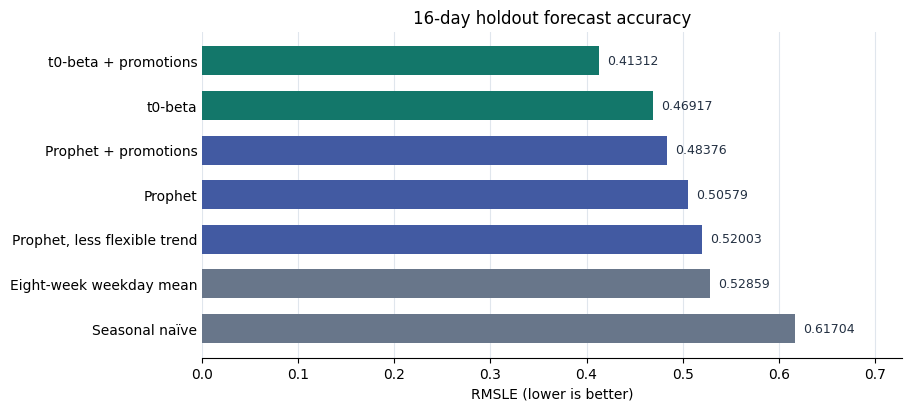

,fold,model,n,rmsle,mae,seconds
0,Development 1,t0-beta + promotions,28512,0.38570,54.91,102.28
1,Development 1,t0-beta,28512,0.38972,53.07,42.44
2,Development 1,Eight-week weekday mean,28512,0.40593,61.69,0.01
3,Development 1,"Prophet, less flexible trend",28512,0.44321,98.07,114.74
4,Development 1,Prophet,28512,0.45849,145.98,88.32
5,Development 1,Prophet + promotions,28512,0.46318,250.49,113.73
6,Development 1,Seasonal naïve,28512,0.51762,78.82,0.02
7,Development 2,t0-beta + promotions,28512,0.39344,55.58,104.19
8,Development 2,t0-beta,28512,0.40355,55.58,73.30
9,Development 2,Eight-week weekday mean,28512,0.41697,64.03,0.01


Measured seconds cover fitting and forecasting for Prophet and inference for t0-beta. Checkpoint loading occurs before timing. The recorded jobs shared one CPU, so times describe this run and should not be treated as a deployment speed comparison.

In [3]:
model_labels = {
    "seasonal_naive": "Seasonal naïve",
    "weekday_mean": "Eight-week weekday mean",
    "prophet": "Prophet",
    "prophet_rigid": "Prophet, less flexible trend",
    "prophet_promotion": "Prophet + promotions",
    "t0_beta": "t0-beta",
    "t0_beta_promotion": "t0-beta + promotions",
}
window_labels = {
    "validation_1": "Development 1",
    "validation_2": "Development 2",
    "holdout": "Final holdout",
}
score_columns = ["fold", "model", "n", "rmsle", "mae", "seconds"]
holdout_scores = scores.loc[scores["fold"].eq(holdout_fold)].sort_values("rmsle")

fig, ax = plt.subplots(figsize=(9, 4.0), layout="constrained")
colors = [
    "#13776a"
    if m.startswith("t0")
    else "#425aa2"
    if m.startswith("prophet")
    else "#68768a"
    for m in holdout_scores["model"]
]
bars = ax.barh(
    holdout_scores["model"].map(model_labels),
    holdout_scores["rmsle"],
    color=colors,
    height=0.65,
)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.5f", padding=6, color="#233042", fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e0e6ed")
ax.set_xlim(0, holdout_scores["rmsle"].max() * 1.18)
ax.set(
    xlabel="RMSLE (lower is better)",
    title="16-day holdout forecast accuracy"
    if dataset != "fixture"
    else "Fixture holdout",
)
plt.show()

score_table = scores.sort_values(["forecast_start", "rmsle"])[score_columns].copy()
score_table["model"] = score_table["model"].map(model_labels)
score_table["fold"] = score_table["fold"].map(window_labels)
display(score_table.reset_index(drop=True).round({"rmsle": 5, "mae": 2, "seconds": 2}))
display(
    Markdown(
        "Measured seconds cover fitting and forecasting for Prophet and inference for t0-beta. "
        "Checkpoint loading occurs before timing. The recorded jobs shared one CPU, so times "
        "describe this run and should not be treated as a deployment speed comparison."
    )
)

## Compare models with the same inputs

The model family comparison holds the forecast dates, scoring rows, and availability of promotion information fixed. Within each family, the promotion comparison changes which predictors are available. Relative RMSLE reductions are measured against the corresponding Prophet configuration.

The development-selected setting and the lowest realized error in the final holdout answer different questions. The development selection determines the competition refit. The final holdout describes forecast accuracy in a period left out of selection.

In [4]:
if dataset == "fixture":
    display(Markdown("This table and figure verify scoring on the generated fixture."))
else:
    best = holdout_scores.iloc[0]
    display(
        Markdown(
            f"**Development selection:** {model_labels[manifest['selected_model']]}.  \n"
            f"**Lowest observed holdout RMSLE:** {best['rmsle']:.5f} "
            f"({model_labels[best['model']]}, {int(best['n']):,} forecasts)."
        )
    )

development = pd.Series(manifest["development_rmsle"], name="Pooled development RMSLE")
display(development.rename(index=model_labels).sort_values().to_frame().round(5))

rmsle_by_window = scores.pivot(index="fold", columns="model", values="rmsle")
rmsle_by_window = rmsle_by_window.reindex(windows["fold"])
comparisons = {}
for label, prophet, t0 in (
    ("History only", "prophet", "t0_beta"),
    ("With promotions", "prophet_promotion", "t0_beta_promotion"),
):
    if {prophet, t0}.issubset(rmsle_by_window.columns):
        comparisons[f"{label} · Prophet"] = rmsle_by_window[prophet]
        comparisons[f"{label} · t0-beta"] = rmsle_by_window[t0]
        comparisons[f"{label} · RMSLE reduction (%)"] = 100 * (
            1 - rmsle_by_window[t0] / rmsle_by_window[prophet]
        )
if comparisons:
    matched_scores = pd.DataFrame(comparisons).rename(index=window_labels)
    display(matched_scores.round(3))

promo_effects = {}
for label, history, with_promo in (
    ("Prophet", "prophet", "prophet_promotion"),
    ("t0-beta", "t0_beta", "t0_beta_promotion"),
):
    if {history, with_promo}.issubset(rmsle_by_window.columns):
        promo_effects[label] = rmsle_by_window[with_promo] - rmsle_by_window[history]
if promo_effects:
    display(
        Markdown(
            "**RMSLE change when adding promotions** (negative values indicate improvement)"
        )
    )
    display(pd.DataFrame(promo_effects).rename(index=window_labels).round(5))

**Development selection:** t0-beta + promotions.  
**Lowest observed holdout RMSLE:** 0.41312 (t0-beta + promotions, 28,512 forecasts).

,Pooled development RMSLE
t0-beta + promotions,0.38959
t0-beta,0.39669
Eight-week weekday mean,0.41149
"Prophet, less flexible trend",0.46266
Prophet + promotions,0.46448
Prophet,0.46520
Seasonal naïve,0.51940


,History only · Prophet,History only · t0-beta,History only · RMSLE reduction (%),With promotions · Prophet,With promotions · t0-beta,With promotions · RMSLE reduction (%)
fold,,,,,,
Development 1,0.458,0.390,14.999,0.463,0.386,16.729
Development 2,0.472,0.404,14.470,0.466,0.393,15.527
Final holdout,0.506,0.469,7.239,0.484,0.413,14.603


**RMSLE change when adding promotions** (negative values indicate improvement)

,Prophet,t0-beta
fold,,
Development 1,0.00470,-0.00402
Development 2,-0.00605,-0.01010
Final holdout,-0.02203,-0.05606


## Where the gains occur

Lead-time scores show whether a model's advantage is concentrated near the forecast origin. Grouped scores pool the underlying squared log errors across days and store–family rows. The promotion groups use the recorded count on each forecast date.

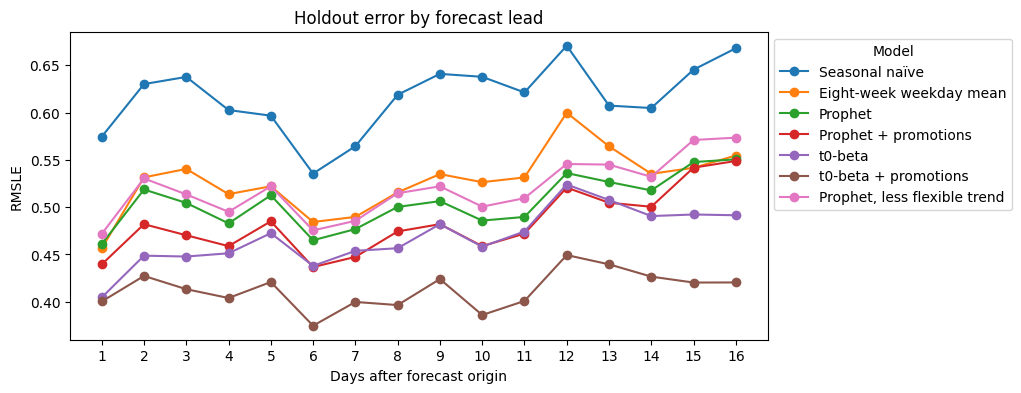

band,Days 1–8,Days 9–16
model,,
Prophet,0.49060,0.52054
Prophet + promotions,0.46206,0.50453
"Prophet, less flexible trend",0.50145,0.53797
Seasonal naïve,0.59594,0.63744
t0-beta,0.44698,0.49037
t0-beta + promotions,0.40482,0.42125
Eight-week weekday mean,0.50737,0.54899


**Where the promotion input reduced t0-beta error**

model,Rows,t0-beta,t0-beta + promotions,Squared log error reduction,Share of net reduction (%)
group,,,,,
no_promotion,16031,0.45481,0.45430,7.39256,0.52421
promotion,12481,0.48700,0.35323,1402.83964,99.47579


In [5]:
holdout_slices = slices.loc[slices["fold"].eq(holdout_fold)]
lead_scores = holdout_slices.loc[holdout_slices["dimension"].eq("horizon_day")].copy()
lead_scores["group"] = lead_scores["group"].astype(int)
lead_table = lead_scores.pivot(
    index="group", columns="model", values="rmsle"
).sort_index()

chart_models = [
    model
    for model in (
        "seasonal_naive",
        "weekday_mean",
        "prophet",
        "prophet_promotion",
        "t0_beta",
        "t0_beta_promotion",
        "prophet_rigid",
    )
    if model in lead_table
]
ax = (
    lead_table[chart_models]
    .rename(columns=model_labels)
    .plot(marker="o", figsize=(9, 4))
)
ax.set(
    xlabel="Days after forecast origin",
    ylabel="RMSLE",
    title="Holdout error by forecast lead",
)
ax.set_xticks(lead_table.index)
ax.legend(title="Model", loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

# Pool squared log errors before taking a square root. This weights dates by row counts.
lead_scores["band"] = pd.cut(
    lead_scores["group"], [0, 8, 16], labels=["Days 1–8", "Days 9–16"]
)
lead_scores["squared_log_error"] = lead_scores["n"] * lead_scores["rmsle"].pow(2)
lead_totals = lead_scores.groupby(["model", "band"], observed=True)[
    ["n", "squared_log_error"]
].sum()
band_rmsle = (lead_totals["squared_log_error"] / lead_totals["n"]).pow(0.5)
display(band_rmsle.unstack().rename(index=model_labels).round(5))

promo_scores = holdout_slices.loc[holdout_slices["dimension"].eq("promotion")].copy()
t0_pair = ["t0_beta", "t0_beta_promotion"]
t0_promo = promo_scores.loc[promo_scores["model"].isin(t0_pair)].copy()
if set(t0_pair) == set(t0_promo["model"]):
    t0_promo["squared_log_error"] = t0_promo["n"] * t0_promo["rmsle"].pow(2)
    group_rmsle = t0_promo.pivot(index="group", columns="model", values="rmsle")
    group_sse = t0_promo.pivot(
        index="group", columns="model", values="squared_log_error"
    )
    gain = group_sse["t0_beta"] - group_sse["t0_beta_promotion"]
    group_rmsle.insert(0, "Rows", t0_promo.groupby("group")["n"].first())
    group_rmsle["Squared log error reduction"] = gain
    if gain.sum() > 0:
        group_rmsle["Share of net reduction (%)"] = 100 * gain / gain.sum()
    display(Markdown("**Where the promotion input reduced t0-beta error**"))
    display(group_rmsle.rename(columns=model_labels).round(5))

## What the confirmed Kaggle-data results show

**The model-family ranking held up.** With promotion inputs matched, t0-beta's RMSLE was **16.7%, 15.5%, and 14.6%** lower than Prophet's over the two development windows and final holdout. With sales history alone, the reductions were **15.0%, 14.5%, and 7.2%**. The eight-week weekday mean stayed competitive in development and beat both history-only Prophet variants in both earlier windows. The more rigid Prophet trend lowered pooled development RMSLE from 0.46520 to 0.46266 and raised it from 0.50579 to 0.52003 on the final holdout. The sensitivity check shows that a tuning choice favored in the earlier windows can lose ground in a later period.

**Promotion information helped most where stores ran promotions.** Adding promotions to t0-beta reduced RMSLE in each window. The first development window went the other way for Prophet. The 12,481 promoted holdout rows were 43.8% of observations and accounted for **99.5% of the net reduction in summed squared log error** when adding promotions to t0-beta. Their RMSLE moved from 0.48700 to 0.35323. RMSLE on the remaining 16,031 rows moved from 0.45481 to 0.45430. The share calculation uses the reduction in squared log errors before taking any square roots.

**The holdout advantage persisted across the horizon.** Promotion-aware t0-beta had the lowest RMSLE of all seven configurations at each of the 16 holdout leads. Its pooled RMSLE increased from **0.40482** on days 1–8 to **0.42125** on days 9–16. Promotion-aware Prophet increased from **0.46206** to **0.50453** across the same bands. Adjacent lead-day results share one forecast origin and related sales shocks. Treat the pattern as descriptive evidence from this horizon.

**The choice depends on the error the decision rewards.** On the holdout, MAE favored the history-only t0-beta at **70.82 units** over the promotion-aware t0-beta at **71.45**. RMSLE measures discrepancies on the log scale, which changes the relative influence of errors on small- and large-volume rows. Mean absolute unit errors offer a second view. Availability, profit, and inventory costs require operational outcomes outside the Kaggle files.

## Decision Loop

| Stage | Application at Favorita |
| --- | --- |
| Learn | At each origin, timestamp available promotion plans, compare the incumbent, a weekday mean, and promotion-aware t0-beta on the same store–family dates. Use the simpler baseline to check how much additional complexity earns. |
| Decide | Pilot the promotion-aware model where planners have reliable schedules. Run forecasts in parallel with the current process before changing orders. Track RMSLE, unit error, and underforecasting by lead alongside stockouts and waste. Set the pilot's success criteria with the teams that face these costs. |
| Repeat | Evaluate new origins as sales and inventory outcomes arrive. Compare results for promoted and unpromoted periods. Revisit the model choice when schedules shift, lead-time performance decays, or stockout and waste measures worsen. |

This analysis covers one Ecuadorian retailer, three adjacent evaluation windows, and sales aggregated by family. The promotion entries may differ from what planning staff knew at past origins. Testing deployment requires timestamped plans, on-hand inventory, lead times, and both stockout and excess-inventory costs. Any measured effects of switching the ordering process would also require a design that separates the forecasting change from concurrent operational changes. [Course Decision Loop](https://eisenhauerio.github.io/courses-business-decisions/decision-loop/index.html)

The MLX run stalled on promotion inputs. The reported benchmark uses the pinned checkpoint on CPU, with matching data hashes and windows across the conventional and foundation runs. The local Kaggle-format file uses the development-selected model at the August 15 origin. This report uses local backtests with observed labels. No Kaggle leaderboard score has been verified.

The [experiment plan](files/experiment-plan.md) records the design, verification checks, and academic disclosure.